# Industry Project: Who Should Get a Coupon? Uplift Modeling for Marketing (Production-Style)

> **Who is this notebook for?** Beginners who know a little scikit-learn and want to see how a retailer decides **who to send a marketing offer to**.
> You do not need the causal-inference math from `01_causal_inference.ipynb`. Every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from `01_causal_inference.ipynb`

| `01_causal_inference.ipynb` | This notebook |
|---|---|
| Explains potential outcomes, matching, IPW, DiD, IV with formulas | Uses one idea (**the effect of a coupon on each customer**) to make a money decision |
| Small toy data with 2 features | A realistic campaign log: 100,000 customers, mixed features, missing values |
| Uses `dowhy` / `econml` | Plain **scikit-learn**: S-, T-, X-learner and class transformation in a few readable lines |
| Ends with an estimated effect | Ends with a **targeting policy, a profit estimate, a saved model, a serving function, monitoring and tests** |

---

### The business problem

You work for a grocery and household retailer with a loyalty program. Marketing wants to email a **$5 coupon** to customers to drive purchases in the next 14 days.

- A purchase brings on average **$25 of margin**.
- If a customer uses the coupon, the shop gives away **$5** (on every coupon purchase, also from people who would have bought anyway!).
- Sending one coupon email costs about **$0.20** (email platform, coupon system, customer-service load).

Last month the team ran a **randomized pilot**: half of the customers, chosen by a coin flip, got the coupon. Now they ask:

> *"Who should get the coupon next month so that we make the most money?"*

The naive answer is "send it to the people most likely to buy". This notebook shows why that is **the wrong target**, and how **uplift modeling** answers the right question: *"for whom does the coupon **change** the decision?"*

### The four kinds of customers

| Type | Buys without coupon? | Buys with coupon? | Should get a coupon? |
|---|---|---|---|
| **Persuadables** | No | Yes | **Yes**, the only group where the coupon creates a sale |
| **Sure things** | Yes | Yes | No: we just give away $5 |
| **Lost causes** | No | No | No: wasted email |
| **Sleeping dogs** | Yes | **No** | **Definitely not**: the email annoys them (unsubscribe, "they only want my money") |

A response model ("who will buy?") loves **sure things**. An uplift model looks for **persuadables** and avoids **sleeping dogs**.

### Table of Contents
1. Setup: imports and one central config
2. Get the data: the randomized pilot campaign
3. Check that the experiment is trustworthy
4. Why "target the most likely buyers" is the wrong goal
5. Split the data: train / validation / test
6. Baseline: a classic response model
7. Uplift models: S-learner, T-learner, X-learner, class transformation
8. Evaluate uplift: uplift-by-decile, Qini curve, AUUC
9. Choose how many customers to target using profit
10. Final, honest comparison on the test set
11. Simulation-only check: did we find the right people?
12. Who are the persuadables? Explaining the policy
13. Save the model with its metadata
14. Serve the policy: a decision function with input validation
15. Monitoring: always keep a random holdout group
16. Automated sanity tests
17. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All business numbers (margin, coupon value, cost per email) live in one `Config`. When finance says "the margin is now $22", you change one line and re-run.

> **Performance tip for shared machines:** gradient boosting in scikit-learn uses all CPU cores through OpenMP. On a busy shared server (CI runners, notebook servers, Kubernetes pods with CPU limits), many threads fighting for the same cores can make training **10-50× slower**. `threadpoolctl` lets you cap the threads; for small tables like ours one thread is plenty.

In [1]:
# ---- Standard library ----
import json                      # save model metadata as readable text
import logging                   # timestamped status messages (better than print in production)
import tempfile                  # temporary folder for the saved model (keeps the repo clean)
import warnings                  # hide noisy library warnings in this tutorial
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import joblib                    # save / load scikit-learn models
import matplotlib.pyplot as plt  # plots
import numpy as np               # arrays and math
import pandas as pd              # tables
import sklearn
from scipy import stats          # chi-square test for the experiment sanity check
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("uplift")
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1, user_api="openmp")   # see the performance tip above: avoid CPU over-subscription


@dataclass(frozen=True)
class Config:
    random_state: int = 42            # fixed seed -> same numbers on every run
    n_customers: int = 100_000        # size of last month's pilot campaign
    margin_per_purchase: float = 25.0 # $ margin from one purchase
    coupon_value: float = 5.0         # $ given away on every purchase made with the coupon
    contact_cost: float = 0.20        # $ cost of sending one coupon email
    treatment_share: float = 0.5      # the pilot gave the coupon to a random 50% of customers
    target: str = "purchased"         # outcome: bought something in the 14 days after the email
    treatment: str = "got_coupon"     # 1 = received the coupon, 0 = control group


CFG = Config()
log.info("scikit-learn %s", sklearn.__version__)
print(CFG)

2026-10-21 17:33:02,802 | INFO | scikit-learn 1.9.0


Config(random_state=42, n_customers=100000, margin_per_purchase=25.0, coupon_value=5.0, contact_cost=0.2, treatment_share=0.5, target='purchased', treatment='got_coupon')


---
## 2. Get the data: the randomized pilot campaign

In a real company this table comes from joining the **campaign log** (who got the coupon) with the **orders table** (who bought in the next 14 days) and a **customer feature snapshot taken BEFORE the campaign**:

```sql
-- Real-life version (not run here)
SELECT f.*, c.got_coupon, COALESCE(o.purchased, 0) AS purchased
FROM   customer_features_2026_09_01 f            -- features frozen before the campaign started
JOIN   campaign_2026_09 c USING (customer_id)    -- random assignment from the pilot
LEFT JOIN (SELECT customer_id, 1 AS purchased FROM orders
           WHERE order_date BETWEEN '2026-09-01' AND '2026-09-14' GROUP BY 1) o USING (customer_id);
```

> ⚠️ **Point-in-time rule:** features must be computed **before** the coupon was sent. A feature like "used a coupon this month" would leak the answer.

Here we simulate such a table so the notebook runs offline. The simulator knows each customer's *true* reaction to the coupon (`true_uplift`), which is **never available in real life**. We keep it in a separate "oracle" table and only use it in Section 11 to check our work.

The hidden behaviour (the model must discover it):
- **Price-sensitive** customers (high share of past purchases made on promotion) and customers who have been **away for 2 to 6 months** react well to coupons.
- **Very frequent** buyers and people who **already open every email** would mostly buy anyway (sure things).
- **Long-time customers who ignore marketing emails** react **negatively** (sleeping dogs).

In [2]:
def make_campaign_log(n: int, seed: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Simulate a randomized coupon pilot. Returns (campaign table, hidden oracle table)."""
    rng = np.random.default_rng(seed)

    # --- Customer features (snapshot taken before the campaign) ---
    recency_days = rng.exponential(45, n).clip(1, 365).round()      # days since last purchase
    orders_12m = rng.poisson(4, n)                                  # number of orders in the last year
    avg_basket = rng.lognormal(3.6, 0.5, n).round(2)               # average basket value in $
    tenure_months = rng.integers(1, 120, n)                         # months in the loyalty program
    email_open_rate = rng.beta(2, 5, n)                             # share of marketing emails opened
    has_app = rng.binomial(1, 0.4, n)                               # uses the mobile app
    channel = rng.choice(["store", "online", "both"], n, p=[0.40, 0.35, 0.25])
    region = rng.choice(["North", "South", "East", "West"], n)
    price_sensitivity = rng.beta(2, 2, n)                           # hidden trait, NOT given to the model
    promo_share = (price_sensitivity + rng.normal(0, 0.15, n)).clip(0, 1)   # observable proxy of it

    # --- Probability to buy WITHOUT a coupon (baseline behaviour) ---
    logit_control = (-2.2 + 0.18 * orders_12m - 0.012 * recency_days + 1.2 * email_open_rate
                     + 0.3 * has_app + 0.2 * (channel == "both"))
    # --- Effect of the coupon on the log-odds: different for every customer ---
    logit_effect = (1.4 * price_sensitivity - 0.1
                    + 0.5 * ((recency_days > 60) & (recency_days < 180))       # "win-back" customers
                    - 1.3 * ((tenure_months > 60) & (email_open_rate < 0.2))   # sleeping dogs
                    - 0.12 * (orders_12m - 4) - 0.8 * email_open_rate)         # sure things need no push
    p_control = 1 / (1 + np.exp(-logit_control))
    p_treated = 1 / (1 + np.exp(-(logit_control + logit_effect)))

    # --- The randomized experiment: a fair coin decides who gets the coupon ---
    got_coupon = rng.binomial(1, CFG.treatment_share, n)
    purchased = rng.binomial(1, np.where(got_coupon == 1, p_treated, p_control))

    df = pd.DataFrame({
        "customer_id": [f"L{1_000_000 + i}" for i in range(n)],
        "recency_days": recency_days, "orders_12m": orders_12m, "avg_basket": avg_basket,
        "tenure_months": tenure_months, "email_open_rate": email_open_rate.round(3),
        "has_app": has_app, "channel": channel, "region": region, "promo_share": promo_share.round(3),
        CFG.treatment: got_coupon, CFG.target: purchased,
    })
    # Real-world mess: no email tracking for some customers, new members have no promo history yet
    df.loc[rng.random(n) < 0.05, "email_open_rate"] = np.nan
    df.loc[df["tenure_months"] < 3, "promo_share"] = np.nan

    oracle = pd.DataFrame({"customer_id": df["customer_id"], "p_control": p_control,
                           "p_treated": p_treated, "true_uplift": p_treated - p_control})
    return df, oracle


campaign, oracle = make_campaign_log(CFG.n_customers, CFG.random_state)
print(f"{len(campaign):,} customers | coupon share {campaign[CFG.treatment].mean():.1%}")
print("Missing values:", campaign.isna().sum()[lambda s: s > 0].to_dict())
campaign.head()

100,000 customers | coupon share 50.0%
Missing values: {'email_open_rate': 4880, 'promo_share': 1688}


,customer_id,recency_days,orders_12m,avg_basket,tenure_months,email_open_rate,has_app,channel,region,promo_share,got_coupon,purchased
0,L1000000,108.0,5,39.00,17,0.289,0,online,East,0.337,1,0
1,L1000001,105.0,2,17.50,118,0.208,0,both,West,0.244,0,0
2,L1000002,107.0,4,27.11,88,0.203,0,both,West,0.600,0,0
3,L1000003,13.0,1,33.31,44,0.301,0,online,West,0.875,0,0
4,L1000004,4.0,5,68.34,104,0.294,1,online,West,0.913,1,1


---
## 3. Check that the experiment is trustworthy

Uplift modeling only works on data where the coupon was given **at random** (or at least where we know exactly how it was given). Before modeling, an analyst always checks:

1. **Sample ratio mismatch (SRM):** we planned 50/50. Is the observed split close enough? A chi-square test with a tiny p-value (< 0.001) means the assignment is broken (bug, bots, lost logs) and the data cannot be trusted.
2. **Covariate balance:** both groups should look alike *before* the campaign. We use the **standardized mean difference (SMD)**; values below 0.1 are considered balanced.
3. **Average effect (ATE):** did the coupon work on average? With randomization, a simple difference of purchase rates is an honest estimate.

In [3]:
# 1. Sample ratio mismatch: compare observed group sizes with the planned 50/50 split
observed = campaign[CFG.treatment].value_counts().sort_index().values          # [control, treated]
expected = np.array([1 - CFG.treatment_share, CFG.treatment_share]) * len(campaign)
chi2, srm_p = stats.chisquare(observed, expected)
print(f"Control {observed[0]:,} | Treated {observed[1]:,} | SRM p-value = {srm_p:.3f}"
      f" -> {'OK' if srm_p > 0.001 else 'BROKEN EXPERIMENT, STOP'}")

# 2. Covariate balance: standardized mean difference for every numeric feature
numeric_cols = ["recency_days", "orders_12m", "avg_basket", "tenure_months", "email_open_rate",
                "has_app", "promo_share"]
treated, control = campaign[campaign[CFG.treatment] == 1], campaign[campaign[CFG.treatment] == 0]
smd = ((treated[numeric_cols].mean() - control[numeric_cols].mean())
       / np.sqrt((treated[numeric_cols].var() + control[numeric_cols].var()) / 2))
print("\nLargest |SMD| =", round(smd.abs().max(), 4), "(below 0.1 = balanced)")

# 3. Average treatment effect with a 95% confidence interval (difference of two proportions)
p_t, p_c = treated[CFG.target].mean(), control[CFG.target].mean()
se = np.sqrt(p_t * (1 - p_t) / len(treated) + p_c * (1 - p_c) / len(control))
ate = p_t - p_c
print(f"\nPurchase rate: coupon {p_t:.2%} vs no coupon {p_c:.2%}")
print(f"Average uplift (ATE) = {ate:+.2%}  (95% CI {ate - 1.96 * se:+.2%} to {ate + 1.96 * se:+.2%})")

Control 50,029 | Treated 49,971 | SRM p-value = 0.854 -> OK

Largest |SMD| = 0.0107 (below 0.1 = balanced)

Purchase rate: coupon 24.81% vs no coupon 20.46%
Average uplift (ATE) = +4.34%  (95% CI +3.83% to +4.86%)


The experiment looks healthy, and the coupon works **on average** (a few percentage points more buyers). Now the money question: is it worth sending it to *everyone*?

Per customer, the expected profit of sending a coupon is

`profit = uplift × $25 margin  −  P(buy with coupon) × $5 coupon  −  $0.20 email`

The second term is the trap: we pay the $5 to **every** coupon buyer, including the sure things who would have bought anyway.

In [4]:
def campaign_profit(n_targeted: int, rate_treated: float, rate_control: float, cfg: Config = CFG) -> float:
    """Expected incremental profit ($) of sending the coupon to n_targeted customers."""
    uplift = rate_treated - rate_control
    per_customer = uplift * cfg.margin_per_purchase - rate_treated * cfg.coupon_value - cfg.contact_cost
    return n_targeted * per_customer


blanket = campaign_profit(len(campaign), p_t, p_c)
print(f"Profit if we send the coupon to ALL {len(campaign):,} customers: ${blanket:,.0f}")
print(f"  incremental margin ${ate * CFG.margin_per_purchase * len(campaign):,.0f}"
      f" | coupon cost ${p_t * CFG.coupon_value * len(campaign):,.0f}"
      f" | email cost ${CFG.contact_cost * len(campaign):,.0f}")

Profit if we send the coupon to ALL 100,000 customers: $-35,426
  incremental margin $108,606 | coupon cost $124,032 | email cost $20,000


Sending the coupon to everybody **loses money**: the extra sales do not pay for the discounts given to people who would have bought anyway. So targeting is not a nice-to-have, it decides whether the campaign is profitable at all.

---
## 4. Why "target the most likely buyers" is the wrong goal

The classic approach is a **response model**: predict *P(buy)* and send coupons to the top scores. Let's look at the raw data first: split customers by how often they bought last year and measure the **observed uplift** in each group (purchase rate with coupon minus without).

In [5]:
def uplift_by_group(df: pd.DataFrame, group: pd.Series) -> pd.DataFrame:
    """Purchase rate with/without coupon and the observed uplift for each group."""
    out = (df.assign(group=group)
             .groupby(["group", CFG.treatment], observed=True)[CFG.target].mean()
             .unstack())
    out.columns = ["rate_no_coupon", "rate_coupon"]
    out["observed_uplift"] = out["rate_coupon"] - out["rate_no_coupon"]
    out["customers"] = df.assign(group=group).groupby("group", observed=True).size()
    return out.round(3)


freq_bucket = pd.cut(campaign["orders_12m"], [-1, 1, 3, 5, 7, 100], labels=["0-1", "2-3", "4-5", "6-7", "8+"])
uplift_by_group(campaign, freq_bucket)

,rate_no_coupon,rate_coupon,observed_uplift,customers
group,,,,
0-1,0.128,0.215,0.087,8990
2-3,0.166,0.232,0.066,34385
4-5,0.206,0.254,0.048,35408
6-7,0.274,0.271,-0.002,16118
8+,0.370,0.297,-0.072,5099


Read this table carefully, it is the core lesson of uplift modeling:
- The **frequent buyers (8+ orders)** have the **highest purchase rate**, so a response model ranks them first, but their observed uplift is **negative** (and close to zero for 6-7 orders). They are *sure things* and some *sleeping dogs*: the coupon only costs us money there.
- The occasional buyers buy less often, but the coupon **changes their behaviour** much more.

"Likely to buy" and "likely to be **influenced**" are different questions. We need a model of the **difference** between the two worlds (coupon vs no coupon). That is called the **uplift** or **CATE** (conditional average treatment effect).

---
## 5. Split the data: train / validation / test

- **Train (50%)**: fit the models.
- **Validation (20%)**: choose the model and *how many customers to target*.
- **Test (30%)**: used **once** at the end to report honest numbers.

We stratify on the combination of treatment and outcome so every part keeps the same mix. The test set is large on purpose: uplift is a *small difference between two noisy rates*, so it needs many customers to measure.

In [6]:
FEATURES = ["recency_days", "orders_12m", "avg_basket", "tenure_months", "email_open_rate",
            "has_app", "channel", "region", "promo_share"]
CATEGORICAL = ["channel", "region"]


def prepare_features(df: pd.DataFrame) -> pd.DataFrame:
    """Select model inputs and give text columns a pandas 'category' type (HistGB handles them natively)."""
    X = df[FEATURES].copy()
    for col in CATEGORICAL:
        X[col] = pd.Categorical(X[col], categories=sorted(campaign[col].unique()))
    return X


strata = campaign[CFG.treatment].astype(str) + "_" + campaign[CFG.target].astype(str)
train_df, rest_df = train_test_split(campaign, test_size=0.5, stratify=strata, random_state=CFG.random_state)
valid_df, test_df = train_test_split(rest_df, test_size=0.6, stratify=strata.loc[rest_df.index],
                                     random_state=CFG.random_state)
for name, part in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):6,} rows | coupon share {part[CFG.treatment].mean():.3f}"
          f" | purchase rate {part[CFG.target].mean():.3f}")

X_train, t_train, y_train = prepare_features(train_df), train_df[CFG.treatment].values, train_df[CFG.target].values
X_valid, X_test = prepare_features(valid_df), prepare_features(test_df)

train: 50,000 rows | coupon share 0.500 | purchase rate 0.226
valid: 20,000 rows | coupon share 0.500 | purchase rate 0.226
test : 30,000 rows | coupon share 0.500 | purchase rate 0.226


---
## 6. Baseline: a classic response model

We train the model most companies start with: *"probability to buy if we send a coupon"*, learned on the customers who **got** the coupon. Gradient-boosted trees (`HistGradientBoostingClassifier`) are the industry default for tabular data; they handle missing values and categories without extra preprocessing.

All models in this notebook use the **same** settings, so the comparison is fair.

In [7]:
def make_classifier() -> HistGradientBoostingClassifier:
    """One shared recipe for every classifier in the notebook (fair comparison)."""
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4,
                                          min_samples_leaf=100,          # big leaves = smooth, less overfitting
                                          categorical_features="from_dtype",
                                          random_state=CFG.random_state)


def make_regressor() -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=4, min_samples_leaf=100,
                                         categorical_features="from_dtype", random_state=CFG.random_state)


is_treated = t_train == 1
response_model = make_classifier().fit(X_train[is_treated], y_train[is_treated])   # only coupon receivers


def score_response(X: pd.DataFrame) -> np.ndarray:
    """Higher = more likely to buy (NOT more likely to be influenced)."""
    return response_model.predict_proba(X)[:, 1]

---
## 7. Uplift models: four simple "meta-learners"

A **meta-learner** is a recipe that turns ordinary classifiers into an uplift estimator. You can use any model inside (here: gradient boosting). These recipes are what libraries like `causalml`, `econml` and `scikit-uplift` implement; written by hand they are only a few lines.

| Learner | Idea in one sentence |
|---|---|
| **S-learner** ("single") | One model with `got_coupon` as an extra feature; uplift = prediction with coupon − prediction without |
| **T-learner** ("two") | One model for coupon receivers, one for the control group; uplift = difference of the two predictions |
| **X-learner** | Start from the T-learner, then learn the *individual* imputed effects directly (often better when effects are small) |
| **Class transformation** | Turn the problem into one classifier with a clever label `Z`; works when treatment was 50/50 random |

### 7a. S-learner
Simple, but if the treatment effect is small compared with the other signals, trees may hardly ever split on `got_coupon`, which shrinks the uplift towards zero.

In [8]:
s_model = make_classifier().fit(X_train.assign(got_coupon=t_train), y_train)


def score_s_learner(X: pd.DataFrame) -> np.ndarray:
    p_with = s_model.predict_proba(X.assign(got_coupon=1))[:, 1]     # same customer, coupon world
    p_without = s_model.predict_proba(X.assign(got_coupon=0))[:, 1]  # same customer, no-coupon world
    return p_with - p_without

### 7b. T-learner
Two independent models. Easy to explain to stakeholders: "this is how likely you are to buy with a coupon, this is without".

In [9]:
t_model_treated = make_classifier().fit(X_train[is_treated], y_train[is_treated])    # P(buy | coupon, x)
t_model_control = make_classifier().fit(X_train[~is_treated], y_train[~is_treated])  # P(buy | no coupon, x)


def score_t_learner(X: pd.DataFrame) -> np.ndarray:
    return t_model_treated.predict_proba(X)[:, 1] - t_model_control.predict_proba(X)[:, 1]

### 7c. X-learner (Künzel et al., 2019)
1. Use the T-learner models to **impute** an individual effect for every training customer:
   - coupon receivers: `D = actual purchase − predicted purchase without coupon`
   - control customers: `D = predicted purchase with coupon − actual purchase`
2. Fit two **regressors** that predict `D` from the features.
3. Average them (with 50/50 randomization the propensity weight is simply 0.5).

In [10]:
imputed_treated = y_train[is_treated] - t_model_control.predict_proba(X_train[is_treated])[:, 1]
imputed_control = t_model_treated.predict_proba(X_train[~is_treated])[:, 1] - y_train[~is_treated]
x_model_treated = make_regressor().fit(X_train[is_treated], imputed_treated)
x_model_control = make_regressor().fit(X_train[~is_treated], imputed_control)


def score_x_learner(X: pd.DataFrame, propensity: float = CFG.treatment_share) -> np.ndarray:
    # weight each regressor by the propensity, as in the original paper (0.5/0.5 here)
    return propensity * x_model_control.predict(X) + (1 - propensity) * x_model_treated.predict(X)

### 7d. Class transformation (Jaskowski & Jaroszewicz, 2012)
Define a new label `Z = 1` if (coupon **and** bought) **or** (no coupon **and** did not buy). With a 50/50 random split it can be shown that `uplift = 2 · P(Z=1 | x) − 1`. One ordinary classifier, no extra tricks. (It is only valid for a 50/50 randomized split; otherwise use a weighted version.)

In [11]:
z_label = (y_train == t_train).astype(int)        # 1 for (coupon & bought) or (no coupon & not bought)
ct_model = make_classifier().fit(X_train, z_label)


def score_class_transform(X: pd.DataFrame) -> np.ndarray:
    return 2 * ct_model.predict_proba(X)[:, 1] - 1


SCORERS = {
    "Response model (P(buy))": score_response,
    "S-learner": score_s_learner,
    "T-learner": score_t_learner,
    "X-learner": score_x_learner,
    "Class transformation": score_class_transform,
}
log.info("Trained %d scoring approaches", len(SCORERS))

2026-10-21 17:33:25,643 | INFO | Trained 5 scoring approaches


---
## 8. Evaluate uplift: uplift-by-decile, Qini curve, AUUC

**Problem:** we never see a customer's uplift (we can't send *and* not send the coupon to the same person). So we can't compute an error per customer.

**Solution:** evaluate **groups**. Sort customers by the model's score, and in each group compare the purchase rate of coupon receivers vs control customers. Because the coupon was random, this group-level difference is an honest estimate of the group's uplift.

- **Uplift by decile:** a good model shows high uplift in the top deciles and low (even negative) uplift at the bottom.
- **Qini curve:** "how many *extra* purchases do we get if we target the top x% of customers?" (incremental buyers, with the control group re-scaled to the size of the treated group).
- **AUUC / Qini area:** the area between the model's Qini curve and the straight line of random targeting. Bigger is better; 0 means "no better than random".

In [12]:
def uplift_deciles(scores: np.ndarray, df: pd.DataFrame, n_bins: int = 10) -> pd.DataFrame:
    """Observed uplift in each score decile (decile 1 = highest scores)."""
    frame = pd.DataFrame({"score": scores, "t": df[CFG.treatment].values, "y": df[CFG.target].values})
    frame["decile"] = pd.qcut(frame["score"].rank(method="first", ascending=False), n_bins,
                              labels=range(1, n_bins + 1))
    g = frame.groupby(["decile", "t"], observed=True)["y"].mean().unstack()
    return pd.DataFrame({"rate_coupon": g[1], "rate_no_coupon": g[0], "observed_uplift": g[1] - g[0]})


def qini_curve(scores: np.ndarray, df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Return (fraction targeted, incremental buyers) for targeting the top-k customers by score."""
    order = np.argsort(-scores)                                    # best customers first
    t = df[CFG.treatment].values[order]
    y = df[CFG.target].values[order]
    n_t, n_c = np.cumsum(t), np.cumsum(1 - t)                      # treated / control seen so far
    buyers_t, buyers_c = np.cumsum(y * t), np.cumsum(y * (1 - t))
    ratio = np.divide(n_t, n_c, out=np.zeros(len(n_t)), where=n_c > 0)
    incremental = buyers_t - buyers_c * ratio                      # Radcliffe's Qini formula
    fraction = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0, fraction], np.r_[0, incremental]


def qini_area(scores: np.ndarray, df: pd.DataFrame) -> float:
    """Area between the model's Qini curve and random targeting, per customer (higher is better)."""
    x, q = qini_curve(scores, df)
    random_line = x * q[-1]                                       # random targeting = straight line
    return float(np.trapezoid(q - random_line, x))


valid_scores = {name: scorer(X_valid) for name, scorer in SCORERS.items()}
pd.DataFrame({name: uplift_deciles(s, valid_df)["observed_uplift"] for name, s in valid_scores.items()}).round(3)

,Response model (P(buy)),S-learner,T-learner,X-learner,Class transformation
decile,,,,,
1,0.092,0.130,0.154,0.147,0.116
2,0.082,0.127,0.098,0.141,0.133
3,0.083,0.121,0.107,0.101,0.092
4,0.070,0.074,0.071,0.070,0.078
5,0.046,0.039,0.064,0.070,0.060
6,0.064,0.029,0.019,0.016,0.035
7,0.035,0.041,0.023,-0.005,0.021
8,0.029,0.021,0.022,0.051,-0.005
9,-0.015,-0.021,-0.007,-0.052,-0.016


Each column is a model, each row a decile (1 = the 10% of customers the model likes best). Look at the **first column**: the response model's top deciles do **not** have the highest uplift. The uplift learners put the high-uplift customers on top and the negative-uplift customers (sleeping dogs) at the bottom.

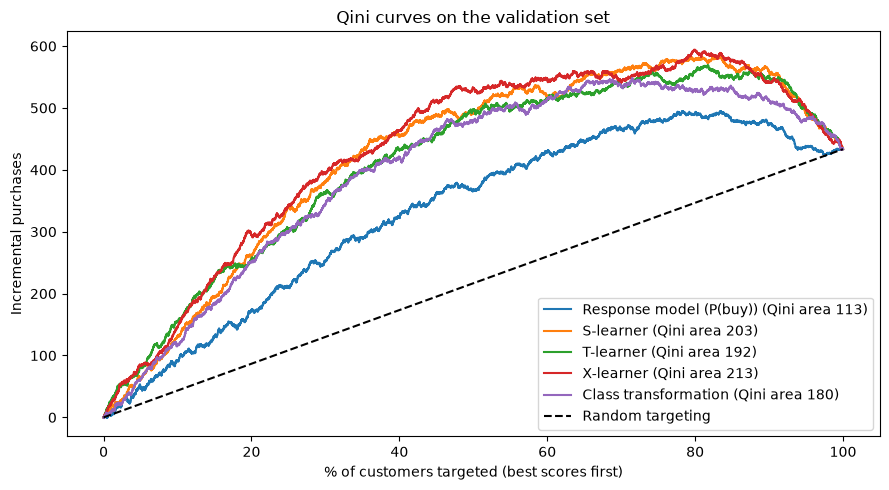

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, s in valid_scores.items():
    x, q = qini_curve(s, valid_df)
    ax.plot(x * 100, q, label=f"{name} (Qini area {qini_area(s, valid_df):.0f})")
ax.plot([0, 100], [0, q[-1]], "k--", label="Random targeting")
ax.set_xlabel("% of customers targeted (best scores first)")
ax.set_ylabel("Incremental purchases")
ax.set_title("Qini curves on the validation set")
ax.legend(); plt.tight_layout(); plt.show()

**How to read the Qini curve:**
- The curve **rises** while we add persuadables and **falls** when we start adding sleeping dogs.
- The **peak** is where the most extra purchases happen, usually well before 100%.
- The end point (100%) is the same for all models: if you target everybody, the ranking doesn't matter.

---
## 9. Choose how many customers to target using profit

Extra purchases are not the same as extra profit (remember the $5 given away to sure things). So we convert the curve into **dollars** for each targeting percentage, using the formula from Section 3 inside the top-k group. We pick the percentage on the **validation** set and freeze it before touching the test set.

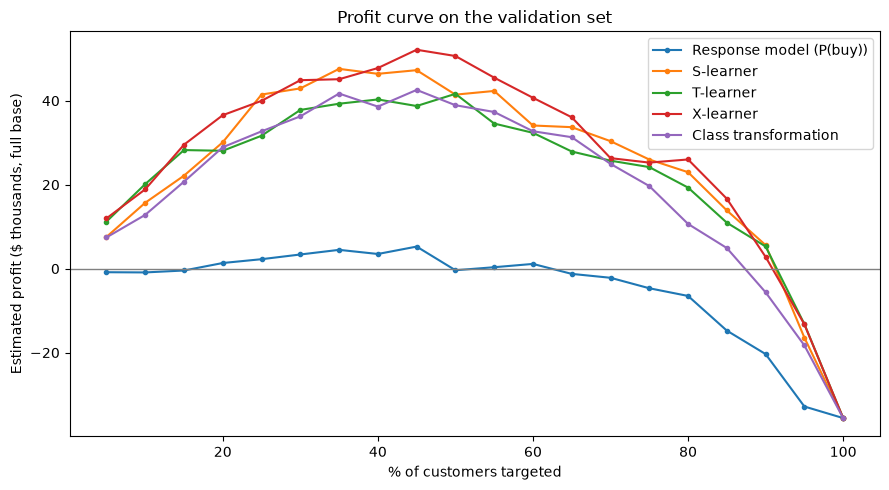

,best_target_%,best_profit_$,qini_area
X-learner,45.0,52144.0,213.1
S-learner,35.0,47593.0,203.3
Class transformation,45.0,42576.0,180.1
T-learner,50.0,41643.0,192.3
Response model (P(buy)),45.0,5256.0,112.6


In [14]:
TARGET_FRACTIONS = np.round(np.arange(0.05, 1.0001, 0.05), 2)


def profit_curve(scores: np.ndarray, df: pd.DataFrame, fractions=TARGET_FRACTIONS) -> pd.Series:
    """Estimated campaign profit (scaled to the full customer base) for each targeting fraction."""
    order = np.argsort(-scores)
    t = df[CFG.treatment].values[order]
    y = df[CFG.target].values[order]
    profits = {}
    for frac in fractions:
        k = int(round(frac * len(df)))
        top_t, top_y = t[:k], y[:k]
        rate_t, rate_c = top_y[top_t == 1].mean(), top_y[top_t == 0].mean()
        # scale from this sample to the full customer base so numbers are comparable to Section 3
        profits[frac] = campaign_profit(int(frac * CFG.n_customers), rate_t, rate_c)
    return pd.Series(profits)


valid_profit = pd.DataFrame({name: profit_curve(s, valid_df) for name, s in valid_scores.items()})

fig, ax = plt.subplots(figsize=(9, 5))
for name in valid_profit:
    ax.plot(valid_profit.index * 100, valid_profit[name] / 1000, marker=".", label=name)
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("% of customers targeted"); ax.set_ylabel("Estimated profit ($ thousands, full base)")
ax.set_title("Profit curve on the validation set"); ax.legend(); plt.tight_layout(); plt.show()

best_fraction = valid_profit.idxmax()            # best targeting % for each model (validation only!)
summary_valid = pd.DataFrame({"best_target_%": (best_fraction * 100).round(0),
                              "best_profit_$": valid_profit.max().round(0),
                              "qini_area": {n: round(qini_area(s, valid_df), 1) for n, s in valid_scores.items()}})
summary_valid.sort_values("best_profit_$", ascending=False)

In [15]:
# Pick the production model: the uplift learner with the best validation profit.
uplift_only = summary_valid.drop(index="Response model (P(buy))")
CHOSEN_MODEL = uplift_only["best_profit_$"].idxmax()
CHOSEN_FRACTION = float(best_fraction[CHOSEN_MODEL])
# Turn "top X%" into a score threshold, so single customers can be scored later (Section 14)
SCORE_THRESHOLD = float(np.quantile(valid_scores[CHOSEN_MODEL], 1 - CHOSEN_FRACTION))
log.info("Chosen: %s | target top %.0f%% | score threshold %.4f", CHOSEN_MODEL, CHOSEN_FRACTION * 100, SCORE_THRESHOLD)

2026-10-21 17:33:37,229 | INFO | Chosen: X-learner | target top 45% | score threshold 0.0595


> **Why not just pick the highest point?** In real projects, the profit curve is noisy and often flat near the top. Many teams pick a slightly **smaller** percentage than the peak (less risk, fewer emails, less unsubscribe risk) when the profit difference is small. We keep the peak here for simplicity.

---
## 10. Final, honest comparison on the test set

Now we compare the strategies marketing actually discusses, on customers no model has seen:

| Strategy | Description |
|---|---|
| Nobody | Don't run the campaign ($0) |
| Everyone | Blanket coupon to all customers |
| Random X% | Send to a random X% (what you get without a model) |
| Highest propensity | Response model, top X% (X chosen on validation for that model) |
| Uplift model | Our chosen learner, top X% (X chosen on validation) |

Because the test numbers come from a finite random sample, we also compute a **bootstrap 95% interval**: we re-sample the test customers 300 times and recompute the profit, to see how much the number could move by chance.

In [16]:
def profit_at_fraction(scores: np.ndarray, df: pd.DataFrame, fraction: float) -> float:
    return float(profit_curve(scores, df, fractions=[fraction]).iloc[0])


def bootstrap_profit(scores: np.ndarray, df: pd.DataFrame, fraction: float, n_boot: int = 300) -> tuple:
    """95% bootstrap interval of the profit estimate (re-sampling customers with replacement)."""
    rng = np.random.default_rng(CFG.random_state)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(df), len(df))
        values.append(profit_at_fraction(scores[idx], df.iloc[idx], fraction))
    return np.percentile(values, [2.5, 97.5])


test_scores = {name: scorer(X_test) for name, scorer in SCORERS.items()}
random_scores = np.random.default_rng(0).random(len(test_df))
response_fraction = float(best_fraction["Response model (P(buy))"])

strategies = {
    "Nobody (no campaign)": (None, 0.0),
    "Everyone (blanket coupon)": (random_scores, 1.0),
    f"Random {CHOSEN_FRACTION:.0%}": (random_scores, CHOSEN_FRACTION),
    f"Highest propensity, top {response_fraction:.0%}": (test_scores["Response model (P(buy))"], response_fraction),
    f"{CHOSEN_MODEL}, top {CHOSEN_FRACTION:.0%}": (test_scores[CHOSEN_MODEL], CHOSEN_FRACTION),
}
rows = []
for name, (scores, frac) in strategies.items():
    if scores is None:
        rows.append({"strategy": name, "customers_targeted": 0, "profit_$": 0.0, "95%_interval": "-"})
        continue
    low, high = bootstrap_profit(scores, test_df, frac)
    rows.append({"strategy": name, "customers_targeted": int(frac * CFG.n_customers),
                 "profit_$": round(profit_at_fraction(scores, test_df, frac)),
                 "95%_interval": f"{low:,.0f} to {high:,.0f}"})
test_results = pd.DataFrame(rows).set_index("strategy")
print("Profit estimated on the TEST set and scaled to the full base of", f"{CFG.n_customers:,} customers")
test_results

Profit estimated on the TEST set and scaled to the full base of 100,000 customers


,customers_targeted,profit_$,95%_interval
strategy,,,
Nobody (no campaign),0,0.0,-
Everyone (blanket coupon),100000,-35362.0,"-56,192 to -15,811"
Random 45%,45000,-30935.0,"-43,921 to -17,026"
"Highest propensity, top 45%",45000,7379.0,"-7,611 to 23,958"
"X-learner, top 45%",45000,57003.0,"42,048 to 72,541"


In [17]:
# All uplift learners on the test set, at the fraction each one chose on validation
pd.DataFrame({
    "qini_area_test": {n: round(qini_area(s, test_df), 1) for n, s in test_scores.items()},
    "target_%": (best_fraction * 100).round(0),
    "profit_test_$": {n: round(profit_at_fraction(s, test_df, best_fraction[n])) for n, s in test_scores.items()},
}).sort_values("profit_test_$", ascending=False)

,qini_area_test,target_%,profit_test_$
T-learner,361.9,50.0,58681
X-learner,363.2,45.0,57003
Class transformation,331.5,45.0,52861
S-learner,344.9,35.0,50074
Response model (P(buy)),214.7,45.0,7379


**What the test set tells us** (numbers above):
- The **blanket coupon loses money**, exactly as the pilot's average numbers predicted in Section 3.
- The **highest-propensity** strategy is far behind the uplift models: it spends coupons on sure things. Its bootstrap interval even includes zero, so it might not make money at all.
- The **uplift learners** make a clearly positive profit. The four learners are close to each other on the test set (the second table), and the gaps between them are smaller than the width of the bootstrap interval of a single strategy. Notice that the learner that won on **validation** is not necessarily the best on **test**: that is normal noise, not a mistake. In practice, when the gap is this small, teams pick the learner that is simplest to maintain and explain (the T-learner is a popular choice for exactly that reason).

---
## 11. Simulation-only check: did we find the right people?

Because we simulated the data, we can peek at the **true** uplift of every test customer (impossible in real life). Two checks:
1. **Correlation** between the model's uplift score and the true uplift.
2. **Sleeping dogs** (true uplift below zero): what share of the customers each strategy targets are sleeping dogs?

In [18]:
test_truth = oracle.set_index("customer_id").loc[test_df["customer_id"], "true_uplift"].values
rows = []
for name, s in test_scores.items():
    frac = float(best_fraction[name])
    top = np.argsort(-s)[: int(frac * len(s))]                    # customers this strategy would target
    rows.append({"model": name,
                 "corr_with_true_uplift": round(np.corrcoef(s, test_truth)[0, 1], 3),
                 "avg_true_uplift_of_targeted": round(test_truth[top].mean(), 4),
                 "%_sleeping_dogs_targeted": round((test_truth[top] < 0).mean() * 100, 1)})
print(f"Share of sleeping dogs among ALL test customers: {(test_truth < 0).mean():.1%}")
pd.DataFrame(rows).set_index("model")

Share of sleeping dogs among ALL test customers: 29.2%


,corr_with_true_uplift,avg_true_uplift_of_targeted,%_sleeping_dogs_targeted
model,,,
Response model (P(buy)),0.505,0.0937,14.2
S-learner,0.819,0.1306,0.9
T-learner,0.832,0.1137,3.3
X-learner,0.859,0.1220,1.5
Class transformation,0.761,0.1166,3.9


The uplift learners rank customers much closer to the truth than the response model, and they send far fewer coupons to sleeping dogs. In a real project you can't run this check, which is why the randomized pilot and the Qini/profit evaluation of Sections 8-10 are so important.

---
## 12. Who are the persuadables? Explaining the policy

Marketing will not accept a black box. A simple and very effective explanation: compare the **average profile** of the customers the model targets with those it skips.

In [19]:
chosen_test_scores = test_scores[CHOSEN_MODEL]
targeted_mask = chosen_test_scores >= SCORE_THRESHOLD
profile = pd.DataFrame({
    "targeted": test_df.loc[targeted_mask, numeric_cols].mean(),
    "not_targeted": test_df.loc[~targeted_mask, numeric_cols].mean(),
}).round(3)
profile["difference"] = (profile["targeted"] - profile["not_targeted"]).round(3)
print(f"{CHOSEN_MODEL}: {targeted_mask.mean():.0%} of test customers are above the score threshold")
profile

X-learner: 45% of test customers are above the score threshold


,targeted,not_targeted,difference
recency_days,49.868,41.907,7.961
orders_12m,3.383,4.490,-1.107
avg_basket,41.724,41.345,0.379
tenure_months,51.164,67.242,-16.078
email_open_rate,0.311,0.266,0.045
has_app,0.411,0.391,0.020
promo_share,0.655,0.377,0.278


The targeted group has a much **higher promo share** (price-sensitive), **fewer orders** (fewer sure things), a **shorter tenure** and a **longer recency** (win-back customers), which matches the hidden behaviour we built into the simulator.

One surprise: the targeted group has a slightly **higher** email open rate, although the simulator says that people who open many emails need the coupon less. The reason is the sleeping dogs: long-time customers who **ignore** emails react badly, and the model avoids them. Two effects pull in opposite directions, which is exactly why one-feature-at-a-time intuition can mislead and a model is useful. If a profile made no business sense at all, that would be a reason to investigate before launch. For per-customer explanations you could use SHAP on the uplift model (see `../07_explainability/01_explainability.ipynb`).

---
## 13. Save the model with its metadata

We save everything needed to reproduce a decision: the trained models of the chosen learner, the score threshold, the business assumptions and the evaluation numbers. In a real project this folder would be `models/coupon_uplift/v1/` or a model registry entry (see `../../15_MLOps/05_model_registry/`).

In [20]:
CHOSEN_PARTS = {   # the fitted models each learner needs at prediction time
    "S-learner": {"s_model": s_model},
    "T-learner": {"treated": t_model_treated, "control": t_model_control},
    "X-learner": {"x_treated": x_model_treated, "x_control": x_model_control},
    "Class transformation": {"ct_model": ct_model},
}[CHOSEN_MODEL]

ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="coupon_uplift_"))   # real project: models/coupon_uplift/v1/
joblib.dump(CHOSEN_PARTS, ARTIFACT_DIR / "uplift_models.joblib")
metadata = {
    "model_name": "coupon_uplift", "model_version": "1.0.0", "learner": CHOSEN_MODEL,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__, "features": FEATURES,
    "category_levels": {c: sorted(campaign[c].unique()) for c in CATEGORICAL},
    "score_threshold": SCORE_THRESHOLD, "target_fraction": CHOSEN_FRACTION,
    "training_data": "randomized coupon pilot 2026-09, 50/50 assignment",
    "test_profit_usd": float(test_results.iloc[-1]["profit_$"]),
    "business_assumptions": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in ARTIFACT_DIR.iterdir():
    print(f"{f.name:22s} {f.stat().st_size / 1024:8.1f} KB")

metadata.json               0.9 KB
uplift_models.joblib      293.8 KB


---
## 14. Serve the policy: a decision function with input validation

The CRM system will call our code once per customer (or in a nightly batch). The function:
1. **validates** the input with Pydantic (the same library FastAPI uses),
2. computes the uplift score with the saved models,
3. returns a **decision** with the expected profit, so marketing can see *why*.

In [21]:
from typing import Literal, Optional
from pydantic import BaseModel, Field, ValidationError


class CustomerFeatures(BaseModel):
    """Input contract: exactly the features the model was trained on, with sane ranges."""
    recency_days: float = Field(ge=0, le=3650)
    orders_12m: int = Field(ge=0, le=1000)
    avg_basket: float = Field(gt=0)
    tenure_months: int = Field(ge=0)
    email_open_rate: Optional[float] = Field(default=None, ge=0, le=1)   # may be unknown
    has_app: Literal[0, 1]
    channel: Literal["store", "online", "both"]
    region: Literal["North", "South", "East", "West"]
    promo_share: Optional[float] = Field(default=None, ge=0, le=1)


class CouponPolicy:
    """Loads the saved uplift model once and decides who gets a coupon."""

    def __init__(self, artifact_dir: Path):
        self.parts = joblib.load(artifact_dir / "uplift_models.joblib")
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())

    def _frame(self, records: list[dict]) -> pd.DataFrame:
        rows = [CustomerFeatures(**r).model_dump() for r in records]       # raises on bad input
        X = pd.DataFrame(rows)[self.meta["features"]]
        X = X.astype({"email_open_rate": float, "promo_share": float})       # None -> NaN
        for col, levels in self.meta["category_levels"].items():
            X[col] = pd.Categorical(X[col], categories=levels)
        return X

    def uplift(self, X: pd.DataFrame) -> np.ndarray:
        p, learner = self.parts, self.meta["learner"]
        if learner == "T-learner":
            return p["treated"].predict_proba(X)[:, 1] - p["control"].predict_proba(X)[:, 1]
        if learner == "S-learner":
            return (p["s_model"].predict_proba(X.assign(got_coupon=1))[:, 1]
                    - p["s_model"].predict_proba(X.assign(got_coupon=0))[:, 1])
        if learner == "X-learner":
            return 0.5 * p["x_treated"].predict(X) + 0.5 * p["x_control"].predict(X)
        return 2 * p["ct_model"].predict_proba(X)[:, 1] - 1                  # class transformation

    def decide(self, records: list[dict]) -> list[dict]:
        scores = self.uplift(self._frame(records))
        return [{"uplift_score": round(float(s), 4),
                 "send_coupon": bool(s >= self.meta["score_threshold"]),
                 "reason": ("likely persuadable" if s >= self.meta["score_threshold"]
                            else "would buy anyway / not influenced / may react badly"),
                 "model_version": self.meta["model_version"]} for s in scores]


policy = CouponPolicy(ARTIFACT_DIR)
bargain_hunter = {"recency_days": 90, "orders_12m": 2, "avg_basket": 35.0, "tenure_months": 20,
                  "email_open_rate": 0.15, "has_app": 0, "channel": "online", "region": "North", "promo_share": 0.85}
loyal_ignorer = {"recency_days": 5, "orders_12m": 11, "avg_basket": 60.0, "tenure_months": 96,
                 "email_open_rate": 0.05, "has_app": 1, "channel": "both", "region": "West", "promo_share": 0.10}
for name, customer in [("bargain hunter", bargain_hunter), ("loyal, ignores emails", loyal_ignorer)]:
    print(f"{name:22s} -> {policy.decide([customer])[0]}")

try:
    policy.decide([dict(bargain_hunter, channel="fax", email_open_rate=1.7)])
except ValidationError as err:
    print(f"\nBad request rejected with {err.error_count()} problems:",
          [e["loc"][0] for e in err.errors()])

bargain hunter         -> {'uplift_score': 0.1782, 'send_coupon': True, 'reason': 'likely persuadable', 'model_version': '1.0.0'}
loyal, ignores emails  -> {'uplift_score': -0.246, 'send_coupon': False, 'reason': 'would buy anyway / not influenced / may react badly', 'model_version': '1.0.0'}

Bad request rejected with 2 problems: ['email_open_rate', 'channel']


---
## 15. Monitoring: always keep a random holdout group

The most important production habit in uplift modeling:

> **Never send the coupon to 100% of the targeted customers.** Keep a small **random holdout** (e.g. 10% of the targeted group gets nothing).

Why? Without it you can never measure whether the campaign still creates *extra* sales. Customer behaviour changes (new competitor, inflation, "coupon fatigue"), and the holdout also produces the fresh randomized data you need to **retrain** the model next quarter.

Below we simulate next month's campaign with a 10% holdout and produce the report marketing would get.

In [22]:
def campaign_report(policy: CouponPolicy, customers: pd.DataFrame, oracle_next: pd.DataFrame,
                    holdout_share: float = 0.10, seed: int = 7) -> dict:
    """Score customers, send coupons to the targeted ones except a random holdout, measure the result."""
    rng = np.random.default_rng(seed)
    X = customers[FEATURES].copy()
    for col, levels in policy.meta["category_levels"].items():
        X[col] = pd.Categorical(X[col], categories=levels)
    targeted = policy.uplift(X) >= policy.meta["score_threshold"]
    holdout = targeted & (rng.random(len(customers)) < holdout_share)       # targeted but NOT sent
    sent = targeted & ~holdout
    # Simulate what customers do (in real life: read the orders table 14 days later)
    p = np.where(sent, oracle_next["p_treated"], oracle_next["p_control"])
    bought = rng.binomial(1, p)
    rate_sent, rate_holdout = bought[sent].mean(), bought[holdout].mean()
    return {"customers": len(customers), "targeted": int(targeted.sum()), "holdout": int(holdout.sum()),
            "purchase_rate_sent": round(rate_sent, 4), "purchase_rate_holdout": round(rate_holdout, 4),
            "measured_uplift": round(rate_sent - rate_holdout, 4),
            "est_profit_on_sent_$": round(campaign_profit(int(sent.sum()), rate_sent, rate_holdout))}


next_month, next_oracle = make_campaign_log(40_000, seed=2026)              # a new month of customers
report = campaign_report(policy, next_month, next_oracle)
print(json.dumps(report, indent=2))

{
  "customers": 40000,
  "targeted": 17885,
  "holdout": 1776,
  "purchase_rate_sent": 0.3013,
  "purchase_rate_holdout": 0.1712,
  "measured_uplift": 0.1302,
  "est_profit_on_sent_$": 24923
}


The holdout lets us measure the uplift **inside the targeted group**, and it is much larger than the average uplift of the blanket pilot in Section 3: the targeting works on fresh customers. In production this report runs after every campaign. **Alert** if the measured uplift in the targeted group drops close to zero, or if the profit turns negative. Also monitor the **input features** for drift (PSI, see `../01_supervised/14_industry_churn_prediction.ipynb`) and the **unsubscribe rate**, which is the visible sign of sleeping dogs.

---
## 16. Automated sanity tests
Small `assert`-style tests that would run in CI (see `../../15_MLOps/07_testing_in_ml/`).

In [23]:
def test_randomization_is_healthy():
    assert srm_p > 0.001, "sample ratio mismatch: the experiment data cannot be trusted"
    assert smd.abs().max() < 0.1, "groups are not balanced before the campaign"


def test_uplift_model_beats_response_model():
    assert qini_area(test_scores[CHOSEN_MODEL], test_df) > qini_area(test_scores["Response model (P(buy))"], test_df)


def test_policy_beats_blanket_campaign():
    assert test_results.iloc[-1]["profit_$"] > test_results.loc["Everyone (blanket coupon)", "profit_$"]


def test_missing_optional_fields_are_ok():
    out = policy.decide([dict(bargain_hunter, email_open_rate=None, promo_share=None)])[0]
    assert isinstance(out["send_coupon"], bool)


def test_unknown_category_is_rejected():
    try:
        policy.decide([dict(bargain_hunter, region="Mars")])
    except ValidationError:
        return
    raise AssertionError("invalid region was accepted")


for test in [test_randomization_is_healthy, test_uplift_model_beats_response_model,
             test_policy_beats_blanket_campaign, test_missing_optional_fields_are_ok,
             test_unknown_category_is_rejected]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_randomization_is_healthy
PASSED  test_uplift_model_beats_response_model
PASSED  test_policy_beats_blanket_campaign
PASSED  test_missing_optional_fields_are_ok
PASSED  test_unknown_category_is_rejected


---
## 17. Summary, exercises and resources

| Industry practice | What we did | Where it's used |
|---|---|---|
| Randomized pilot first | 50/50 coupon test before building any model | Every serious marketing team (email, push, discounts) |
| Experiment sanity checks | SRM chi-square, covariate balance (SMD), ATE with CI | Experimentation platforms (see `../11_ab_testing/`) |
| Right target | Model the **uplift**, not P(buy) | Coupons, retention offers, ads, medical treatment choice |
| Meta-learners | S-, T-, X-learner, class transformation with plain sklearn | `causalml`, `econml`, `scikit-uplift` |
| Group-level evaluation | Uplift by decile, Qini curve, Qini area | Standard uplift evaluation |
| Decision by money | Targeting % chosen by profit on validation, reported on test with bootstrap interval | Campaign planning |
| Explain the policy | Profile of targeted vs skipped customers | Stakeholder sign-off |
| Production | Saved models + metadata, validated decision function | CRM / marketing automation |
| Monitoring | Permanent random holdout, campaign report | Measuring true incrementality over time |

### Practice exercises
1. Change `coupon_value` to `2.0` in the `Config`. Does "Everyone" become profitable? How does the best targeting % move?
2. Give the response model its best chance: target only the top 10%. Is it still worse than the uplift models?
3. Make the treatment split 80/20 in the simulator. Which learner breaks (hint: class transformation needs 50/50) and how would you fix it?
4. Add a **budget constraint**: marketing can send at most 15,000 coupons. Which customers get them?
5. Install `scikit-uplift` (`pip install scikit-uplift`) and compare its `qini_auc_score` with our `qini_area`.

### Resources (checked)
- scikit-uplift docs and RetailHero tutorial: https://scikit-uplift.readthedocs.io/en/stable/quick_start.html and https://github.com/maks-sh/scikit-uplift
- Uber CausalML (meta-learners, Qini curves): https://causalml.readthedocs.io/en/stable/index.html and paper https://arxiv.org/abs/2002.11631
- Künzel et al., *Meta-learners for estimating heterogeneous treatment effects* (X-learner): https://arxiv.org/abs/1706.03461
- Hillstrom "MineThatData" email campaign dataset (a real randomized email test, 64,000 customers): https://causeinfer.readthedocs.io/en/latest/data/hillstrom.html
- TensorFlow Decision Forests uplift tutorial (Hillstrom data): https://www.tensorflow.org/decision_forests/tutorials/uplift_colab
- *Causal Inference for the Brave and True* (free book, chapters on meta-learners and uplift evaluation): https://matheusfacure.github.io/python-causality-handbook/

### Related notebooks in this repo
- Theory: `01_causal_inference.ipynb` (potential outcomes, IPW, DoWhy, EconML)
- Experiment statistics: `../11_ab_testing/01_ab_testing.ipynb`
- Cost-based thresholds and lift tables: `../01_supervised/14_industry_churn_prediction.ipynb`
- Model explanations: `../07_explainability/01_explainability.ipynb`